# LeapQuant 教程 (4/5): 窗口机制 —— 误差随步数怎么累积, window / r 怎么选

教程 2 结论: 每步量化滚雪球, 窗口节奏注入次数少; 教程 3 结论: 单次注入误差 0.458%。
这本把两者合体并回答:

1. **256 步长程**下三种方案误差曲线长什么样;
2. 论文最优 `window=16, r=4` (8-bit) 是怎么扫出来的;
3. window / r 的权衡是什么。

In [1]:
import sys, math
import torch

sys.path.insert(0, "/workspace/y00924007/vllm-ascend")  # 开发树 (分支 leapquant-triton-m3)

try:
    import torch_npu  # noqa: F401 — 注册 npu 后端
    DEV = torch.device("npu") if torch.npu.is_available() else torch.device("cpu")
except Exception:
    DEV = torch.device("cpu")

import warnings, logging
warnings.filterwarnings("ignore")
logging.getLogger("vllm").setLevel(logging.ERROR)

torch.manual_seed(20261110)
print(f"torch = {torch.__version__}   device = {DEV}")

torch = 2.10.0+cpu   device = npu


/usr/local/python3.11.10/lib/python3.11/site-packages/torch_npu/_init/core/optional_features.py:20: UserWarning: On the interactive interface, the value of TASK_QUEUE_ENABLE is set to 0 by default. Do not set it to 1 to avoid unexpected errors.
  warnings.warn(


In [2]:
H, K, V = 8, 128, 128        # Qwen3.5-0.8B 单卡 GDN 头几何 (128×128)
B, WINDOW, R = 4, 16, 4      # 批 / 窗口 / 补偿秩 (论文 8-bit 最优)
SCALE = K ** -0.5

def gdn_inputs(B, H, T, K=K, V=V, dev=DEV):
    q = torch.nn.functional.normalize(torch.randn(B, H, T, K, device=dev), dim=-1)
    k = torch.nn.functional.normalize(torch.randn(B, H, T, K, device=dev), dim=-1)
    v = torch.randn(B, H, T, V, device=dev)
    g = -torch.rand(B, H, T, device=dev) * 0.1       # log 域衰减率 ∈ [-0.1, 0)
    beta = torch.rand(B, H, T, device=dev).sigmoid() # delta 门控
    return q, k, v, g, beta

def gdn_step(h, q, k, v, g, beta):
    """一步递推 (逐项拆解见教程 1): 衰减 → delta 修正 → 外积更新。"""
    h = h * g.exp()[..., None, None]
    v_adj = (v - torch.einsum("bhvk,bhk->bhv", h, k)) * beta[..., None]
    return h + torch.einsum("bhv,bhk->bhvk", v_adj, k)

def gdn_out(h, q):
    return torch.einsum("bhvk,bhk->bhv", h, q) * SCALE

def trajectory(inputs, window=None, boundary_fn=None, every_step_fn=None):
    """跑 T 步; 可选在窗口边界 / 每步对状态做一次变换 (量化实验的注入点)。"""
    q, k, v, g, beta = inputs
    B, H, T = q.shape[0], q.shape[1], q.shape[2]
    h = torch.zeros(B, H, V, K, device=q.device)
    outs = []
    for t in range(T):
        h = gdn_step(h, q[:, :, t], k[:, :, t], v[:, :, t], g[:, :, t], beta[:, :, t])
        if every_step_fn is not None:
            h = every_step_fn(h)
        elif boundary_fn is not None and (t + 1) % window == 0:
            h = boundary_fn(h)
        outs.append(gdn_out(h, q[:, :, t]))
    return h, torch.stack(outs, dim=2)

print("GDN 模拟器就绪 (完整拆解见教程 1)")

GDN 模拟器就绪 (完整拆解见教程 1)


## 1. 窗口语义回顾: 误差只在边界"注入"一次

窗口 $w$: 每 $w$ 个 token 做一次 flush (教程 3 的整条流水线), 从量化态 $\hat{S}_0$ 出发
继续 fp32 递推 —— **窗口内部没有任何量化操作**。代数上这等价于论文的窗口展开式;
直觉上: 账本平时记得很准, 每 $w$ 步"誊抄"一次略带失真的副本。

In [3]:
from vllm_ascend.quantization.methods.mamba_state.leapquant.state import (
    QMAX, leap_window_flush,
)

inp1 = gdn_inputs(B, H, WINDOW)                   # 保持随机流与教程 2/3 一致
S_win, _ = trajectory(inp1)
S_snap = leap_window_flush(S_win)                 # 一个窗口末尾拍快照
print(f"一个窗口 (16 token) 末尾 flush 一次: 相对误差 {((S_snap-S_win).norm()/S_win.norm()):.3%}")
print("窗口内 (1..15 步) 无任何量化; 误差全部来自这一次誊抄\n")

INFO 11-10 19:08:36 [__init__.py:52] Available plugins for group vllm.platform_plugins:


INFO 11-10 19:08:36 [__init__.py:54] - ascend -> vllm_ascend:register


INFO 11-10 19:08:36 [__init__.py:57] All plugins in this group will be loaded. Set `VLLM_PLUGINS` to control which plugins to load.


INFO 11-10 19:08:36 [__init__.py:272] Platform plugin ascend is activated


INFO 11-10 19:08:36 [platform.py:85] Breakable CUDAGraph on Ascend is opt-in; using VLLM_USE_BREAKABLE_CUDAGRAPH=0.


[W1110 19:08:43.039254148 NPUCachingAllocator.cpp:204] Warning: The current CANN and HDK(driver) versions require processing for 32 padding size, with memory allocation. (function operator())


一个窗口 (16 token) 末尾 flush 一次: 相对误差 0.458%
窗口内 (1..15 步) 无任何量化; 误差全部来自这一次誊抄



## 2. 256 步三线对比 —— 核心实验

同一组输入, 三条轨迹 (fp32 基线同步推进):

| 轨迹 | 量化器 | 节奏 |
|---|---|---|
| **LeapQuant (window=16)** | 基+双尺度+补偿 | 每 16 步一次 |
| per-tensor int8 / step | 朴素 (教程 2) | **每步** |
| LeapQuant quant / step | 基+双尺度+补偿 | **每步** (量化器好但节奏错) |

In [4]:
T_LONG = 256
inputs = gdn_inputs(B, H, T_LONG)

def leap_at_boundary(h, at_boundary):
    return leap_window_flush(h) if at_boundary else h

def naive_pertensor(h, at_boundary):
    s = h.abs().amax(dim=(-2, -1), keepdim=True).clamp_min(1e-12) / QMAX
    return torch.round(h / s) * s

def naive_leap_every_step(h, at_boundary):
    return leap_window_flush(h)

VARIANTS = {
    "LeapQuant (window=16)": leap_at_boundary,
    "per-tensor int8 / step": naive_pertensor,
    "LeapQuant quant / step": naive_leap_every_step,
}

def compare(state_fns, window=WINDOW, every=32):
    q, k, v, g, beta = inputs
    T = q.shape[2]
    h_ref = torch.zeros(B, H, V, K, device=DEV)
    hs = {n: torch.zeros_like(h_ref) for n in state_fns}
    log = {n: [] for n in state_fns}
    for t in range(T):
        step = (q[:, :, t], k[:, :, t], v[:, :, t], g[:, :, t], beta[:, :, t])
        h_ref = gdn_step(h_ref, *step)
        o_ref = gdn_out(h_ref, q[:, :, t])
        at_boundary = (t + 1) % window == 0
        for n, fn in state_fns.items():
            hs[n] = gdn_step(hs[n], *step)
            hs[n] = fn(hs[n], at_boundary)
            if (t + 1) % every == 0:
                se = ((hs[n] - h_ref).norm() / h_ref.norm()).item()
                oe = ((gdn_out(hs[n], q[:, :, t]) - o_ref).norm() / o_ref.norm()).item()
                log[n].append((t + 1, se, oe))
    return log

log = compare(VARIANTS)
hdr = list(VARIANTS)
print(f"{'step':>5} | " + " | ".join(f"{n:>22}" for n in hdr))
for i in range(len(log[hdr[0]])):
    t = log[hdr[0]][i][0]
    print(f"{t:>5} | " + " | ".join(f"{log[n][i][1]:>22.3%}" for n in hdr))

 step |  LeapQuant (window=16) | per-tensor int8 / step | LeapQuant quant / step
   32 |                 0.529% |                 3.293% |                 1.441%
   64 |                 0.552% |                 3.341% |                 1.553%
   96 |                 0.557% |                 3.362% |                 1.592%
  128 |                 0.562% |                 3.508% |                 1.613%
  160 |                 0.565% |                 3.446% |                 1.628%
  192 |                 0.564% |                 3.380% |                 1.619%
  224 |                 0.559% |                 3.400% |                 1.597%
  256 |                 0.556% |                 3.391% |                 1.582%


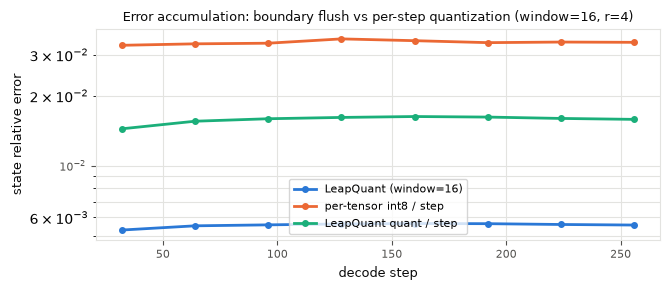

In [5]:
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a"]
fig, ax = plt.subplots(figsize=(6.8, 3.0))
for n, c in zip(VARIANTS, PALETTE):
    ts = [r[0] for r in log[n]]
    es = [r[1] for r in log[n]]
    ax.semilogy(ts, es, color=c, lw=2, marker="o", ms=4, label=n)
ax.set_xlabel("decode step", fontsize=9, color="#0b0b0b")
ax.set_ylabel("state relative error", fontsize=9, color="#0b0b0b")
ax.set_title("Error accumulation: boundary flush vs per-step quantization (window=16, r=4)", fontsize=9, color="#0b0b0b")
ax.grid(True, which="both", color="#e3e3e0", lw=0.8)
for sp in ax.spines.values(): sp.set_color("#e3e3e0")
ax.tick_params(colors="#52514e", labelsize=8)
ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

读图: **每步量化** (两根高线) 误差持续堆积 —— 哪怕量化器换成 LeapQuant 的 (青线)
也只是从 3.4% 降到 ~1.6%, 治标不治本; **窗口 flush** (蓝线) 0.5% 出头且走平 ——
误差只在边界注入, 窗口内不增长, 整体呈**有界平台**。这就是 LeapQuant 的核心主张。

## 3. 超参扫描: window 与 compensator_tokens

两个旋钮:
- `window`: 大 → flush 少 (注入次数↓) 但每次窗口更长、状态能量更散 (单次误差↑);
- `r` (compensator_tokens): fp16 补偿的方向数, 大 → 单次误差↓ 但 fp16 开销↑。

In [6]:
print("window 扫描 (r=4, 256 步):")
for w in (8, 16, 32, 64):
    lg = compare({"leap": leap_at_boundary}, window=w)
    fin = lg["leap"][-1]
    print(f"  window={w:>2}:  状态误差 {fin[1]:.3%}   输出误差 {fin[2]:.3%}")

print("\ncompensator_tokens 扫描 (window=16, 256 步):")
for r in (1, 2, 4, 8):
    fn = (lambda rr: (lambda h, at_b: leap_window_flush(h, compensator_tokens=rr) if at_b else h))(r)
    lg = compare({f"r={r}": fn})
    fin = list(lg.values())[0][-1]
    print(f"  r={r}:  状态误差 {fin[1]:.3%}   输出误差 {fin[2]:.3%}")

window 扫描 (r=4, 256 步):


  window= 8:  状态误差 0.664%   输出误差 0.653%


  window=16:  状态误差 0.556%   输出误差 0.553%


  window=32:  状态误差 0.511%   输出误差 0.503%
  window=64:  状态误差 0.502%   输出误差 0.501%

compensator_tokens 扫描 (window=16, 256 步):


  r=1:  状态误差 0.640%   输出误差 0.620%


  r=2:  状态误差 0.611%   输出误差 0.603%


  r=4:  状态误差 0.556%   输出误差 0.553%


  r=8:  状态误差 0.455%   输出误差 0.444%


## 4. 权衡讨论

- **window**: 8→64 误差从 0.664% 单调降到 0.502%, 但窗口越长, 峰值时刻必须同时拿到的
  fp32 状态越大、flush 读写带宽越高; 16 是论文 8-bit 设置下的甜点 (再大收益递减);
- **r**: 1→8 误差从 0.640% 降到 0.455%; r 走 fp16, 每头多 $2 \times r \times \max(V,K) \times 2$ 字节,
  8-bit 设置下 r=4 即可接近收敛;
- 论文 8-bit 最优: **window=16, r=4** —— 本系列所有实验的默认值。

## 小结 (教程 4)

- 长程误差: 节奏 (窗口) 是一阶因素, 量化器精度是二阶因素 —— "好量化器 + 错节奏"照样 1.6%;
- LeapQuant (w=16, r=4): 256 步误差平台 ~0.55%, 不随步数增长;
- window/r 扫描复现论文 8-bit 最优 w=16 / r=4。

→ **教程 5**: 离开模拟器, 看这套东西在 vllm-ascend 引擎里怎么接线 (配置、due 判定、池级行 flush)。